In [1]:
import pandas as pd
dataset=pd.read_csv("Social_Network_Ads.csv")
dataset=pd.get_dummies(dataset,dtype=int,drop_first=True)
ind=dataset[['Age', 'EstimatedSalary', 'Gender_Male']]
dep=dataset[['Purchased']]

In [2]:
from sklearn.model_selection import train_test_split
xTrain,xTest,yTrain,yTest=train_test_split(ind,dep,test_size=0.30,random_state=0)

In [5]:
from sklearn.preprocessing import StandardScaler
sc=StandardScaler()
xTrain=sc.fit_transform(xTrain)
xTest=sc.transform(xTest)

C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


In [6]:
'''(*, criterion='gini', splitter='best', max_depth=None, min_samples_split=2, min_samples_leaf=1, min_weight_fraction_leaf=0.0,
max_features=None, random_state=None, 
max_leaf_nodes=None, min_impurity_decrease=0.0, class_weight=None, ccp_alpha=0.0, monotonic_cst=None)'''
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV
param_grid={'criterion':['gini', 'entropy', 'log_loss'],'splitter':['best', 'random'],'max_features':['sqrt', 'log2'],
           'class_weight':['dict','balanced',None]}
grid=GridSearchCV(DecisionTreeClassifier(),param_grid,refit=True,verbose=3,n_jobs=-1,scoring='f1_weighted')
grid.fit(xTrain,yTrain)

Fitting 5 folds for each of 36 candidates, totalling 180 fits


C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\model_selection\_validation.py:489: FitFailedWarning: 
60 fits failed out of a total of 180.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
60 fits failed with the following error:
Traceback (most recent call last):
  File "C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\model_selection\_validation.py", line 851, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\base.py", line 1393, in wrapper
    estimator._validate_params()
    ~~~~~~~~~~~~~~~~~~~~~~~~~~^^
  File "C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\base.py", line 554, in _validate_params
   

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeClassifier()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'class_weight': ['dict', 'balanced', ...], 'criterion': ['gini', 'entropy', ...], 'max_features': ['sqrt', 'log2'], 'splitter': ['best', 'random']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1_weighted'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",3
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier an

In [7]:
gPredict=grid.predict(xTest)

In [8]:
print('Best Score:',grid.best_score_)
print('Best Params:',grid.best_params_)

Best Score: 0.8564101571577751
Best Params: {'class_weight': 'balanced', 'criterion': 'gini', 'max_features': 'log2', 'splitter': 'random'}


In [9]:
from sklearn.metrics import confusion_matrix
cm= confusion_matrix(yTest,gPredict)
cm

array([[ 0, 79],
       [ 0, 41]])

In [10]:
from sklearn.metrics import classification_report
cr=classification_report(yTest,gPredict)
print(cr)

              precision    recall  f1-score   support

           0       0.00      0.00      0.00        79
           1       0.34      1.00      0.51        41

    accuracy                           0.34       120
   macro avg       0.17      0.50      0.25       120
weighted avg       0.12      0.34      0.17       120



C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [11]:
from sklearn.metrics import roc_auc_score
gProb=grid.predict_proba(xTest)[:,1]
roc_auc_score(yTest,gProb)

0.5

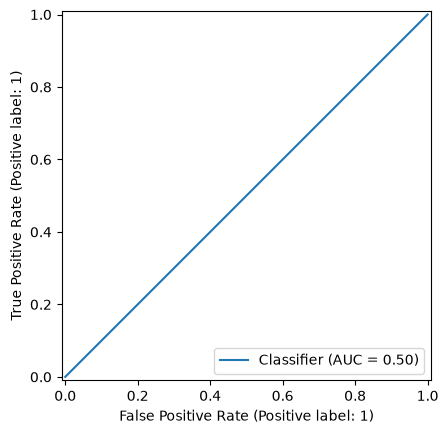

In [13]:
from sklearn.metrics import RocCurveDisplay
RocCurveDisplay.from_predictions(yTest,gProb)

In [14]:
age=int(input("Enter Age:"))
salary=float(input("Enter your salary:"))
sex=int(input("Gender M(1) F(0):"))
grid.predict([[age,salary,sex]])

Enter Age: 44
Enter your salary: 2342
Gender M(1) F(0): 0


array([1])